In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
plt.rcParams["figure.dpi"] = 300
from pathlib import Path

In [2]:
# Base path containing the merged comparison datasets
base = Path("/gws/ssde/j25b/swift/mendrika/asnie/paper")

# Paths for each storm-object comparison
path_core_roa = base / "core-vs-roa"
path_core_crr = base / "core-vs-crr"

path_rdt_roa = base / "rdt-vs-roa"
path_rdt_crr = base / "rdt-vs-crr"

path_ts_roa = base / "ts-vs-roa"
path_ts_crr = base / "ts-vs-crr"


# Load Core comparisons
core_roa = pd.read_parquet(path_core_roa / "core.parquet")
roa_core = pd.read_parquet(path_core_roa / "roa.parquet")

core_crr = pd.read_parquet(path_core_crr / "core.parquet")
crr_core = pd.read_parquet(path_core_crr / "crr.parquet")


# Load RDT comparisons
rdt_roa = pd.read_parquet(path_rdt_roa / "rdt.parquet")
roa_rdt = pd.read_parquet(path_rdt_roa / "roa.parquet")

rdt_crr = pd.read_parquet(path_rdt_crr / "rdt.parquet")
crr_rdt = pd.read_parquet(path_rdt_crr / "crr.parquet")

# Rename RDT coordinates to use the same convention as the other products
rdt_roa = rdt_roa.rename(
    columns={
        "lat": "lat_centroid",
        "lon": "lon_centroid",
    }
)

rdt_crr = rdt_crr.rename(
    columns={
        "lat": "lat_centroid",
        "lon": "lon_centroid",
    }
)


# Load DWD-TS comparisons
ts_roa = pd.read_parquet(path_ts_roa / "ts.parquet")
roa_ts = pd.read_parquet(path_ts_roa / "roa.parquet")

ts_crr = pd.read_parquet(path_ts_crr / "ts.parquet")
crr_ts = pd.read_parquet(path_ts_crr / "crr.parquet")


# Print dataset sizes
print("Core vs RoA:", len(core_roa), len(roa_core))
print("Core vs CRR:", len(core_crr), len(crr_core))

print("RDT vs RoA:", len(rdt_roa), len(roa_rdt))
print("RDT vs CRR:", len(rdt_crr), len(crr_rdt))

print("DWD-TS vs RoA:", len(ts_roa), len(roa_ts))
print("DWD-TS vs CRR:", len(ts_crr), len(crr_ts))

Core vs RoA: 27734335 5950027
Core vs CRR: 2341299 960246
RDT vs RoA: 2920249 864949
RDT vs CRR: 1897802 1013031
DWD-TS vs RoA: 2299331 1195442
DWD-TS vs CRR: 502612 475741


In [3]:
def latlon_to_xy_km(lat, lon):
    """
    Convert latitude and longitude coordinates to approximate Cartesian
    coordinates in kilometres using an equirectangular projection.

    A single reference latitude, defined as the mean latitude of all supplied
    points, is used to scale the longitude coordinate. This ensures that the
    same longitude scaling is applied to every point in the dataset.

    Parameters
    ----------
    lat : array-like
        Latitudes in degrees.
    lon : array-like
        Longitudes in degrees.

    Returns
    -------
    xy : ndarray of shape (N, 2)
        Cartesian coordinates in kilometres, with columns corresponding
        to x (east-west) and y (north-south).
    """

    R = 6371.0

    lat_rad = np.deg2rad(lat)
    lon_rad = np.deg2rad(lon)

    # Use one reference latitude for consistent longitude scaling
    lat_ref = np.mean(lat_rad)

    x = R * lon_rad * np.cos(lat_ref)
    y = R * lat_rad

    return np.column_stack((x, y))

In [4]:
def object_to_rain_distances(df_object, df_rain, start_hour=0, end_hour=23):
    """
    Compute the distance from each storm object to the nearest rainfall object
    at the same timestep, restricted to convectively active hours.
    """

    matches = []

    # Restrict both datasets to the selected hours using the timestamp column
    object_active = df_object[
        (df_object["timestamp"].dt.hour >= start_hour)
        & (df_object["timestamp"].dt.hour <= end_hour)
    ]

    rain_active = df_rain[
        (df_rain["timestamp"].dt.hour >= start_hour)
        & (df_rain["timestamp"].dt.hour <= end_hour)
    ]

    # Compare storm objects only with rainfall objects from the same timestamp
    for t, object_group in object_active.groupby("timestamp"):

        rain_group = rain_active[rain_active["timestamp"] == t]

        if len(rain_group) == 0:
            continue

        # Convert rainfall centroids to Cartesian coordinates
        rain_xy = latlon_to_xy_km(
            rain_group["lat_centroid"].values,
            rain_group["lon_centroid"].values,
        )

        tree = cKDTree(rain_xy)

        # Convert storm-object centroids to Cartesian coordinates
        object_xy = latlon_to_xy_km(
            object_group["lat_centroid"].values,
            object_group["lon_centroid"].values,
        )

        # Find the nearest rainfall object for each storm object
        distances, _ = tree.query(object_xy, k=1)

        matches.extend(distances)

    return np.array(matches)

In [5]:
domains = ["CA", "EA", "SA", "WA"]

distances = {}

for domain in domains:

    # Select the current domain for each Core comparison
    core_roa_domain = core_roa[core_roa["domain"] == domain]
    roa_core_domain = roa_core[roa_core["domain"] == domain]

    core_crr_domain = core_crr[core_crr["domain"] == domain]
    crr_core_domain = crr_core[crr_core["domain"] == domain]

    # Select the current domain for each RDT comparison
    rdt_roa_domain = rdt_roa[rdt_roa["domain"] == domain]
    roa_rdt_domain = roa_rdt[roa_rdt["domain"] == domain]

    rdt_crr_domain = rdt_crr[rdt_crr["domain"] == domain]
    crr_rdt_domain = crr_rdt[crr_rdt["domain"] == domain]

    # Select the current domain for each DWD-TS comparison
    ts_roa_domain = ts_roa[ts_roa["domain"] == domain]
    roa_ts_domain = roa_ts[roa_ts["domain"] == domain]

    ts_crr_domain = ts_crr[ts_crr["domain"] == domain]
    crr_ts_domain = crr_ts[crr_ts["domain"] == domain]

    # Compute nearest-object distances for the current domain
    distances[domain] = {
        "core_roa": object_to_rain_distances(
            core_roa_domain, roa_core_domain
        ),
        "core_crr": object_to_rain_distances(
            core_crr_domain, crr_core_domain
        ),
        "rdt_roa": object_to_rain_distances(
            rdt_roa_domain, roa_rdt_domain
        ),
        "rdt_crr": object_to_rain_distances(
            rdt_crr_domain, crr_rdt_domain
        ),
        "ts_roa": object_to_rain_distances(
            ts_roa_domain, roa_ts_domain
        ),
        "ts_crr": object_to_rain_distances(
            ts_crr_domain, crr_ts_domain
        ),
    }

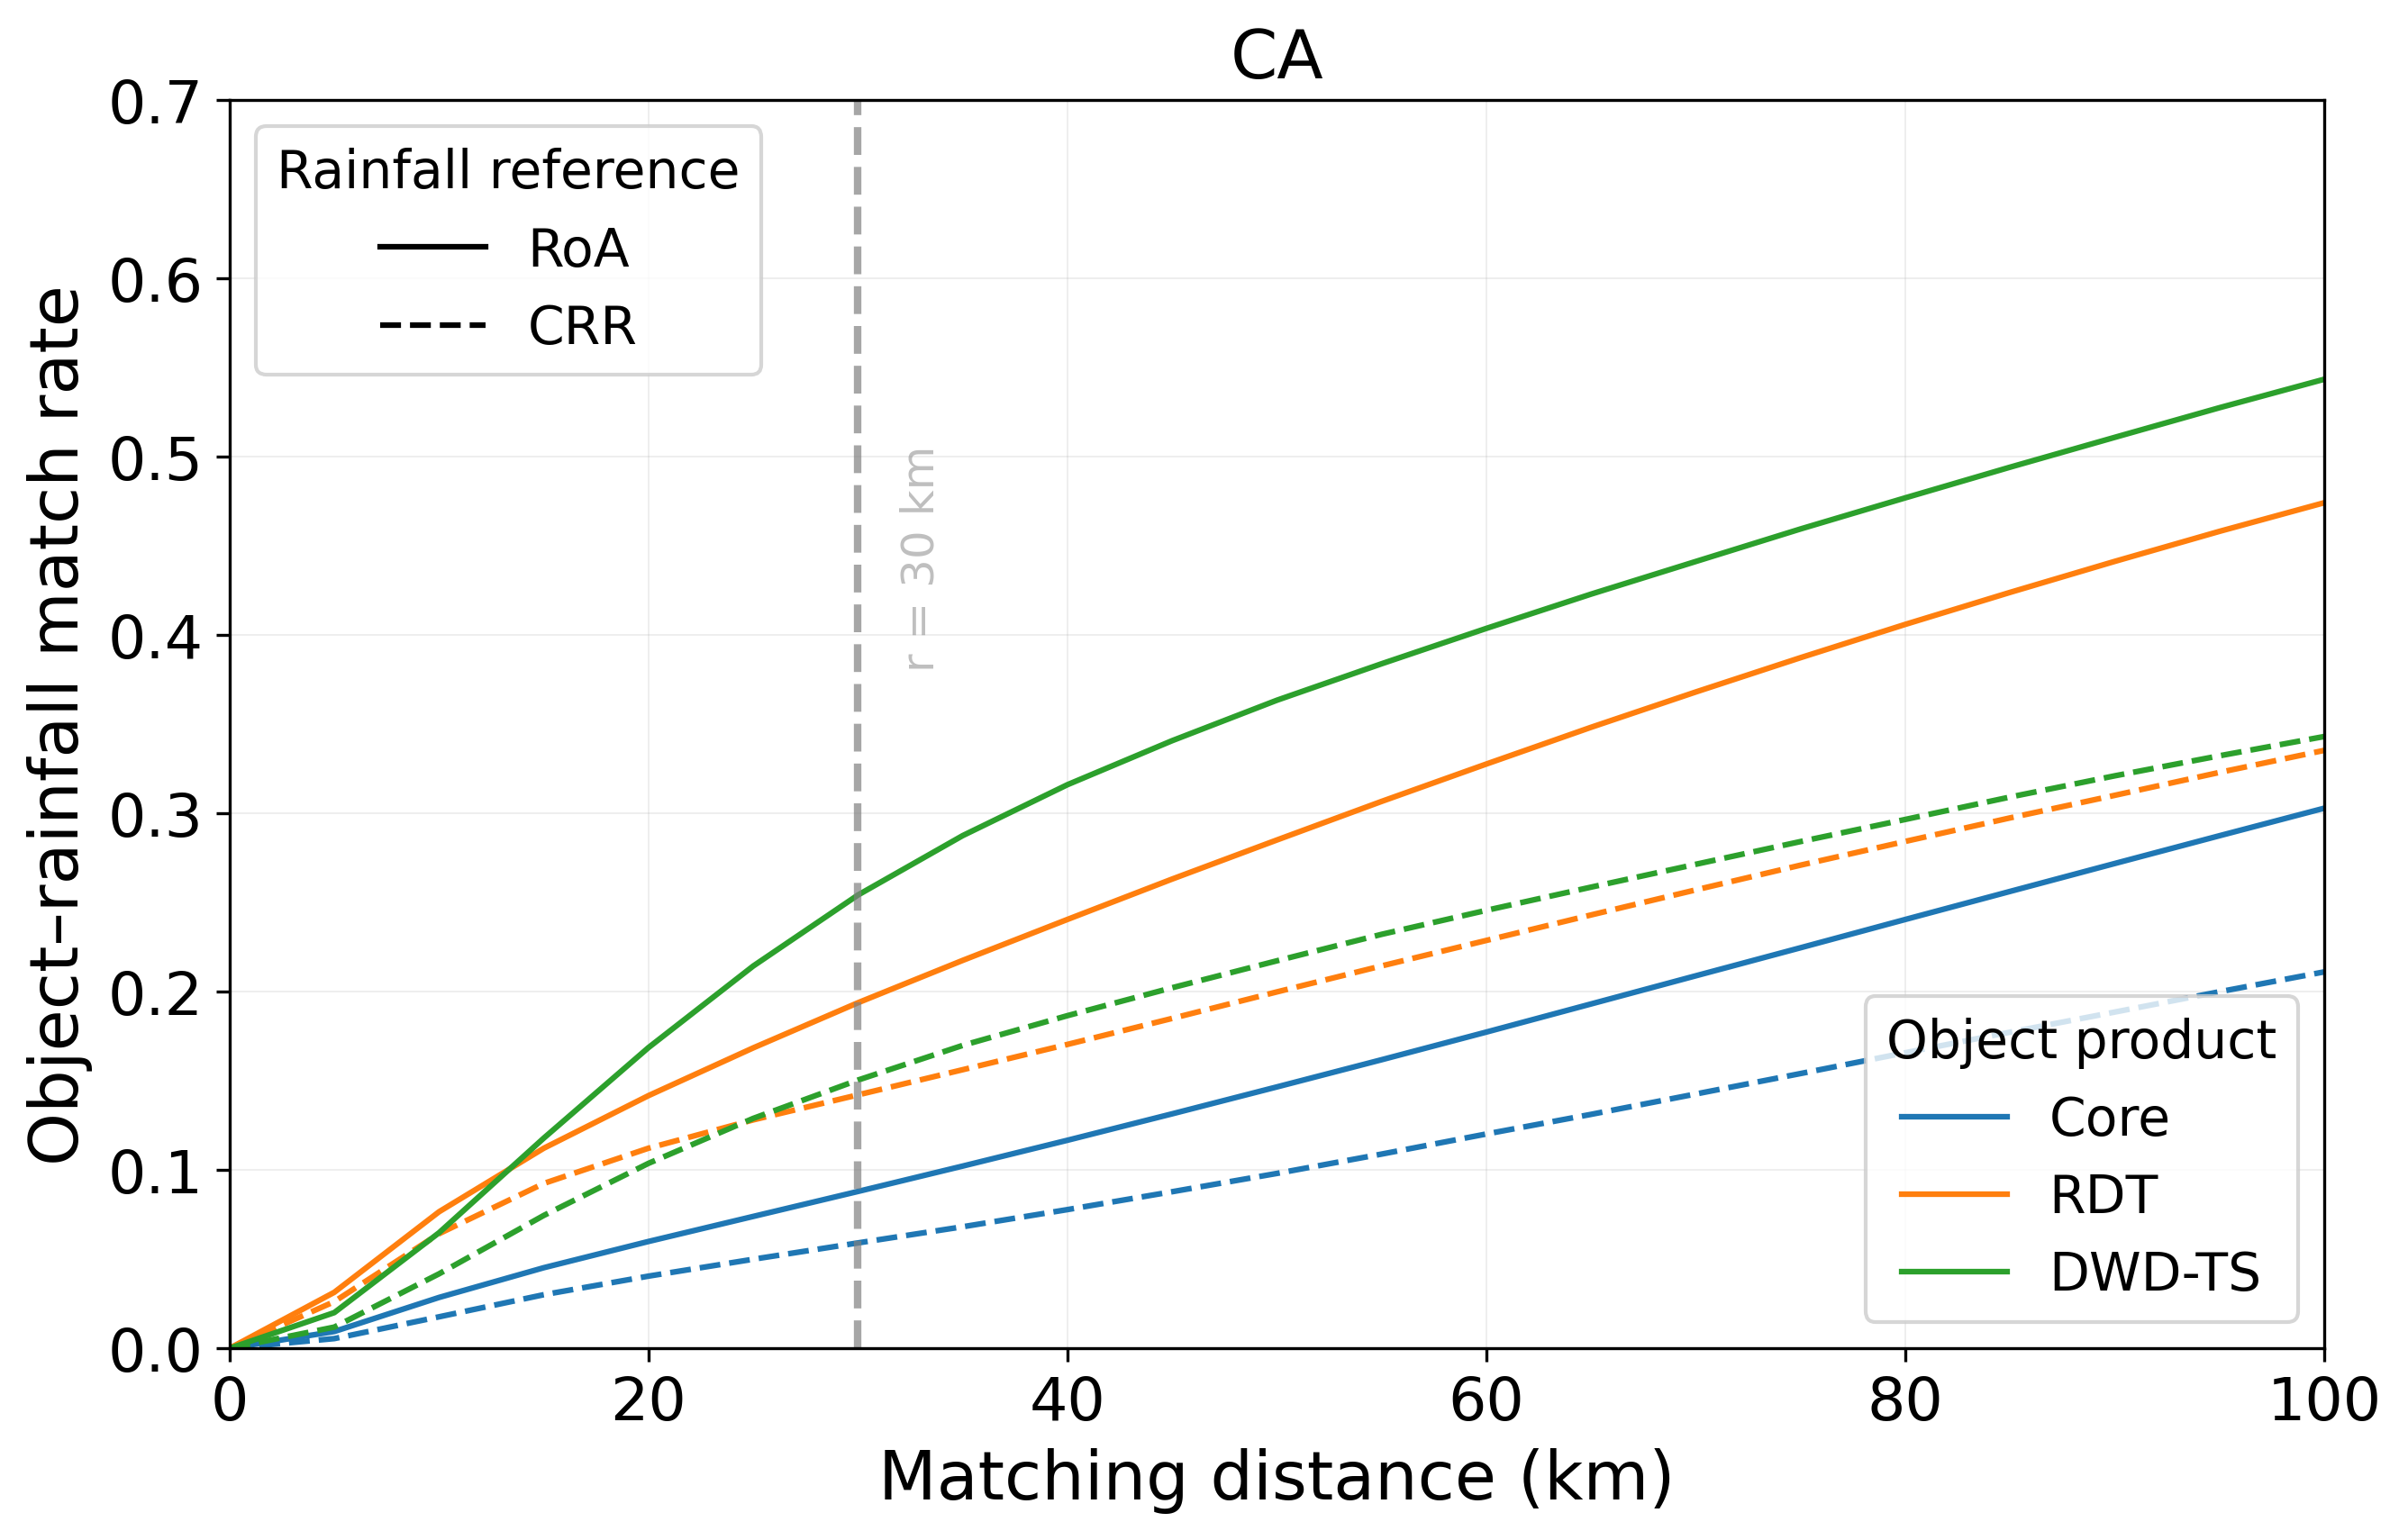

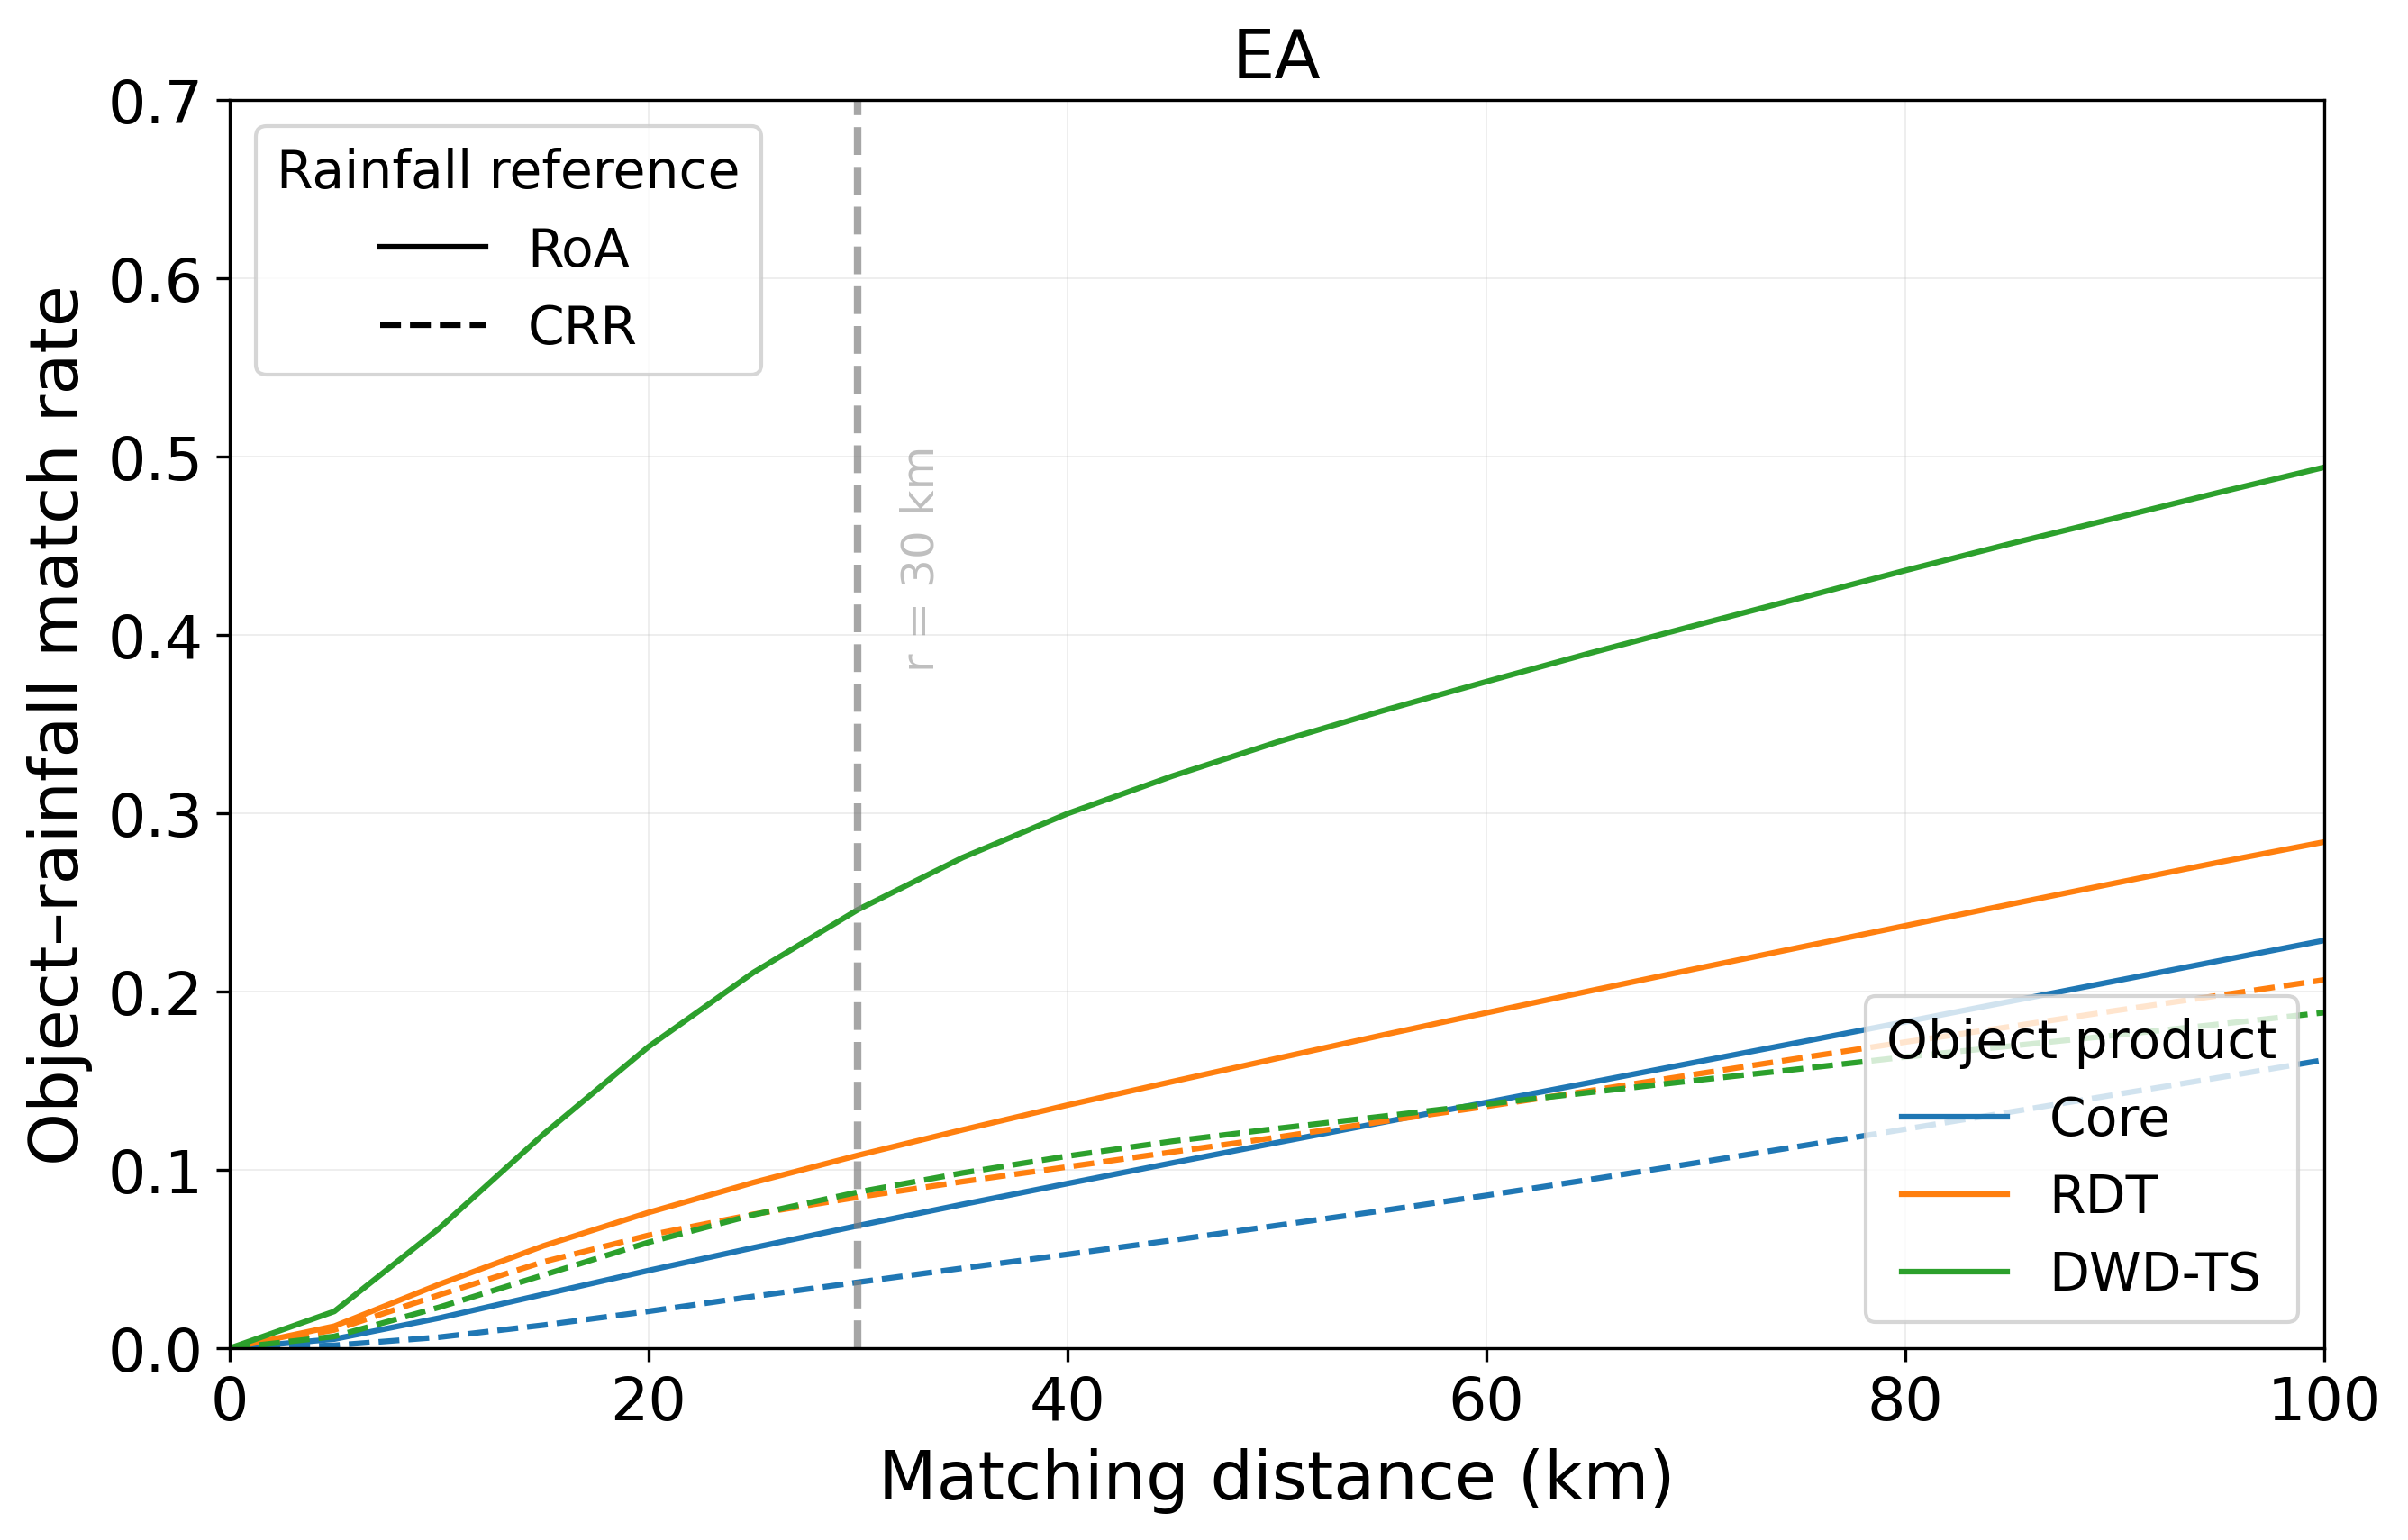

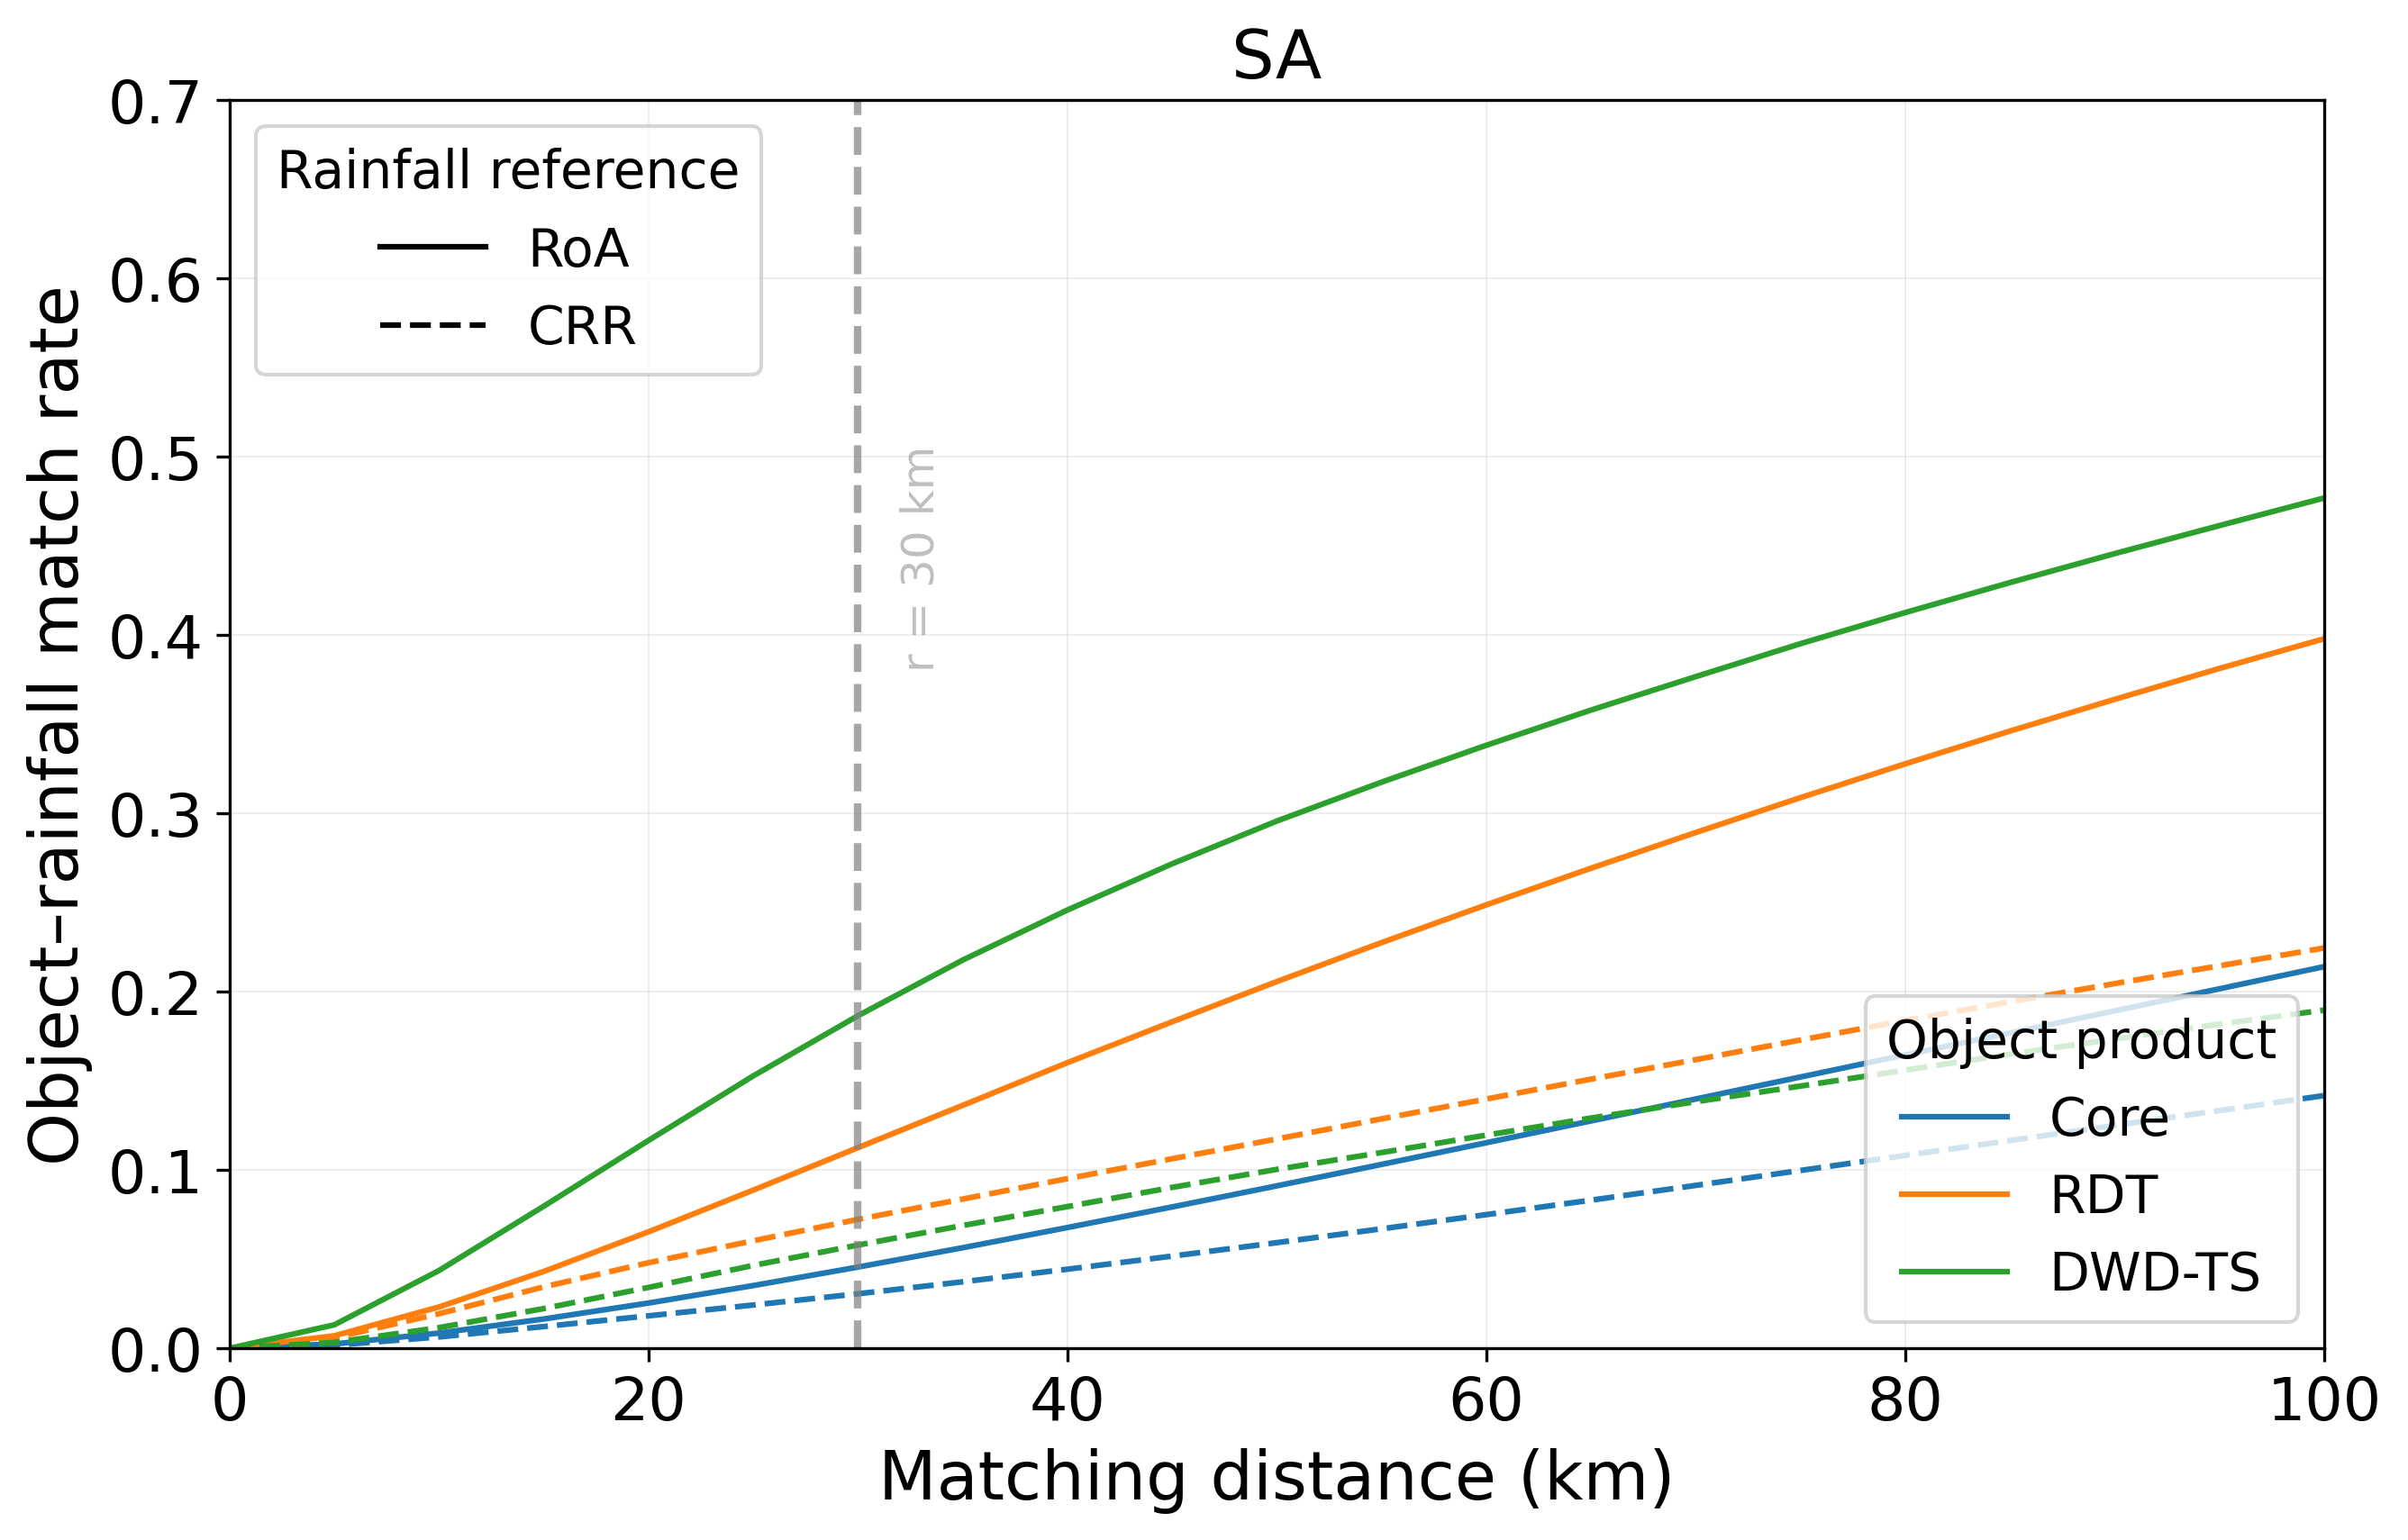

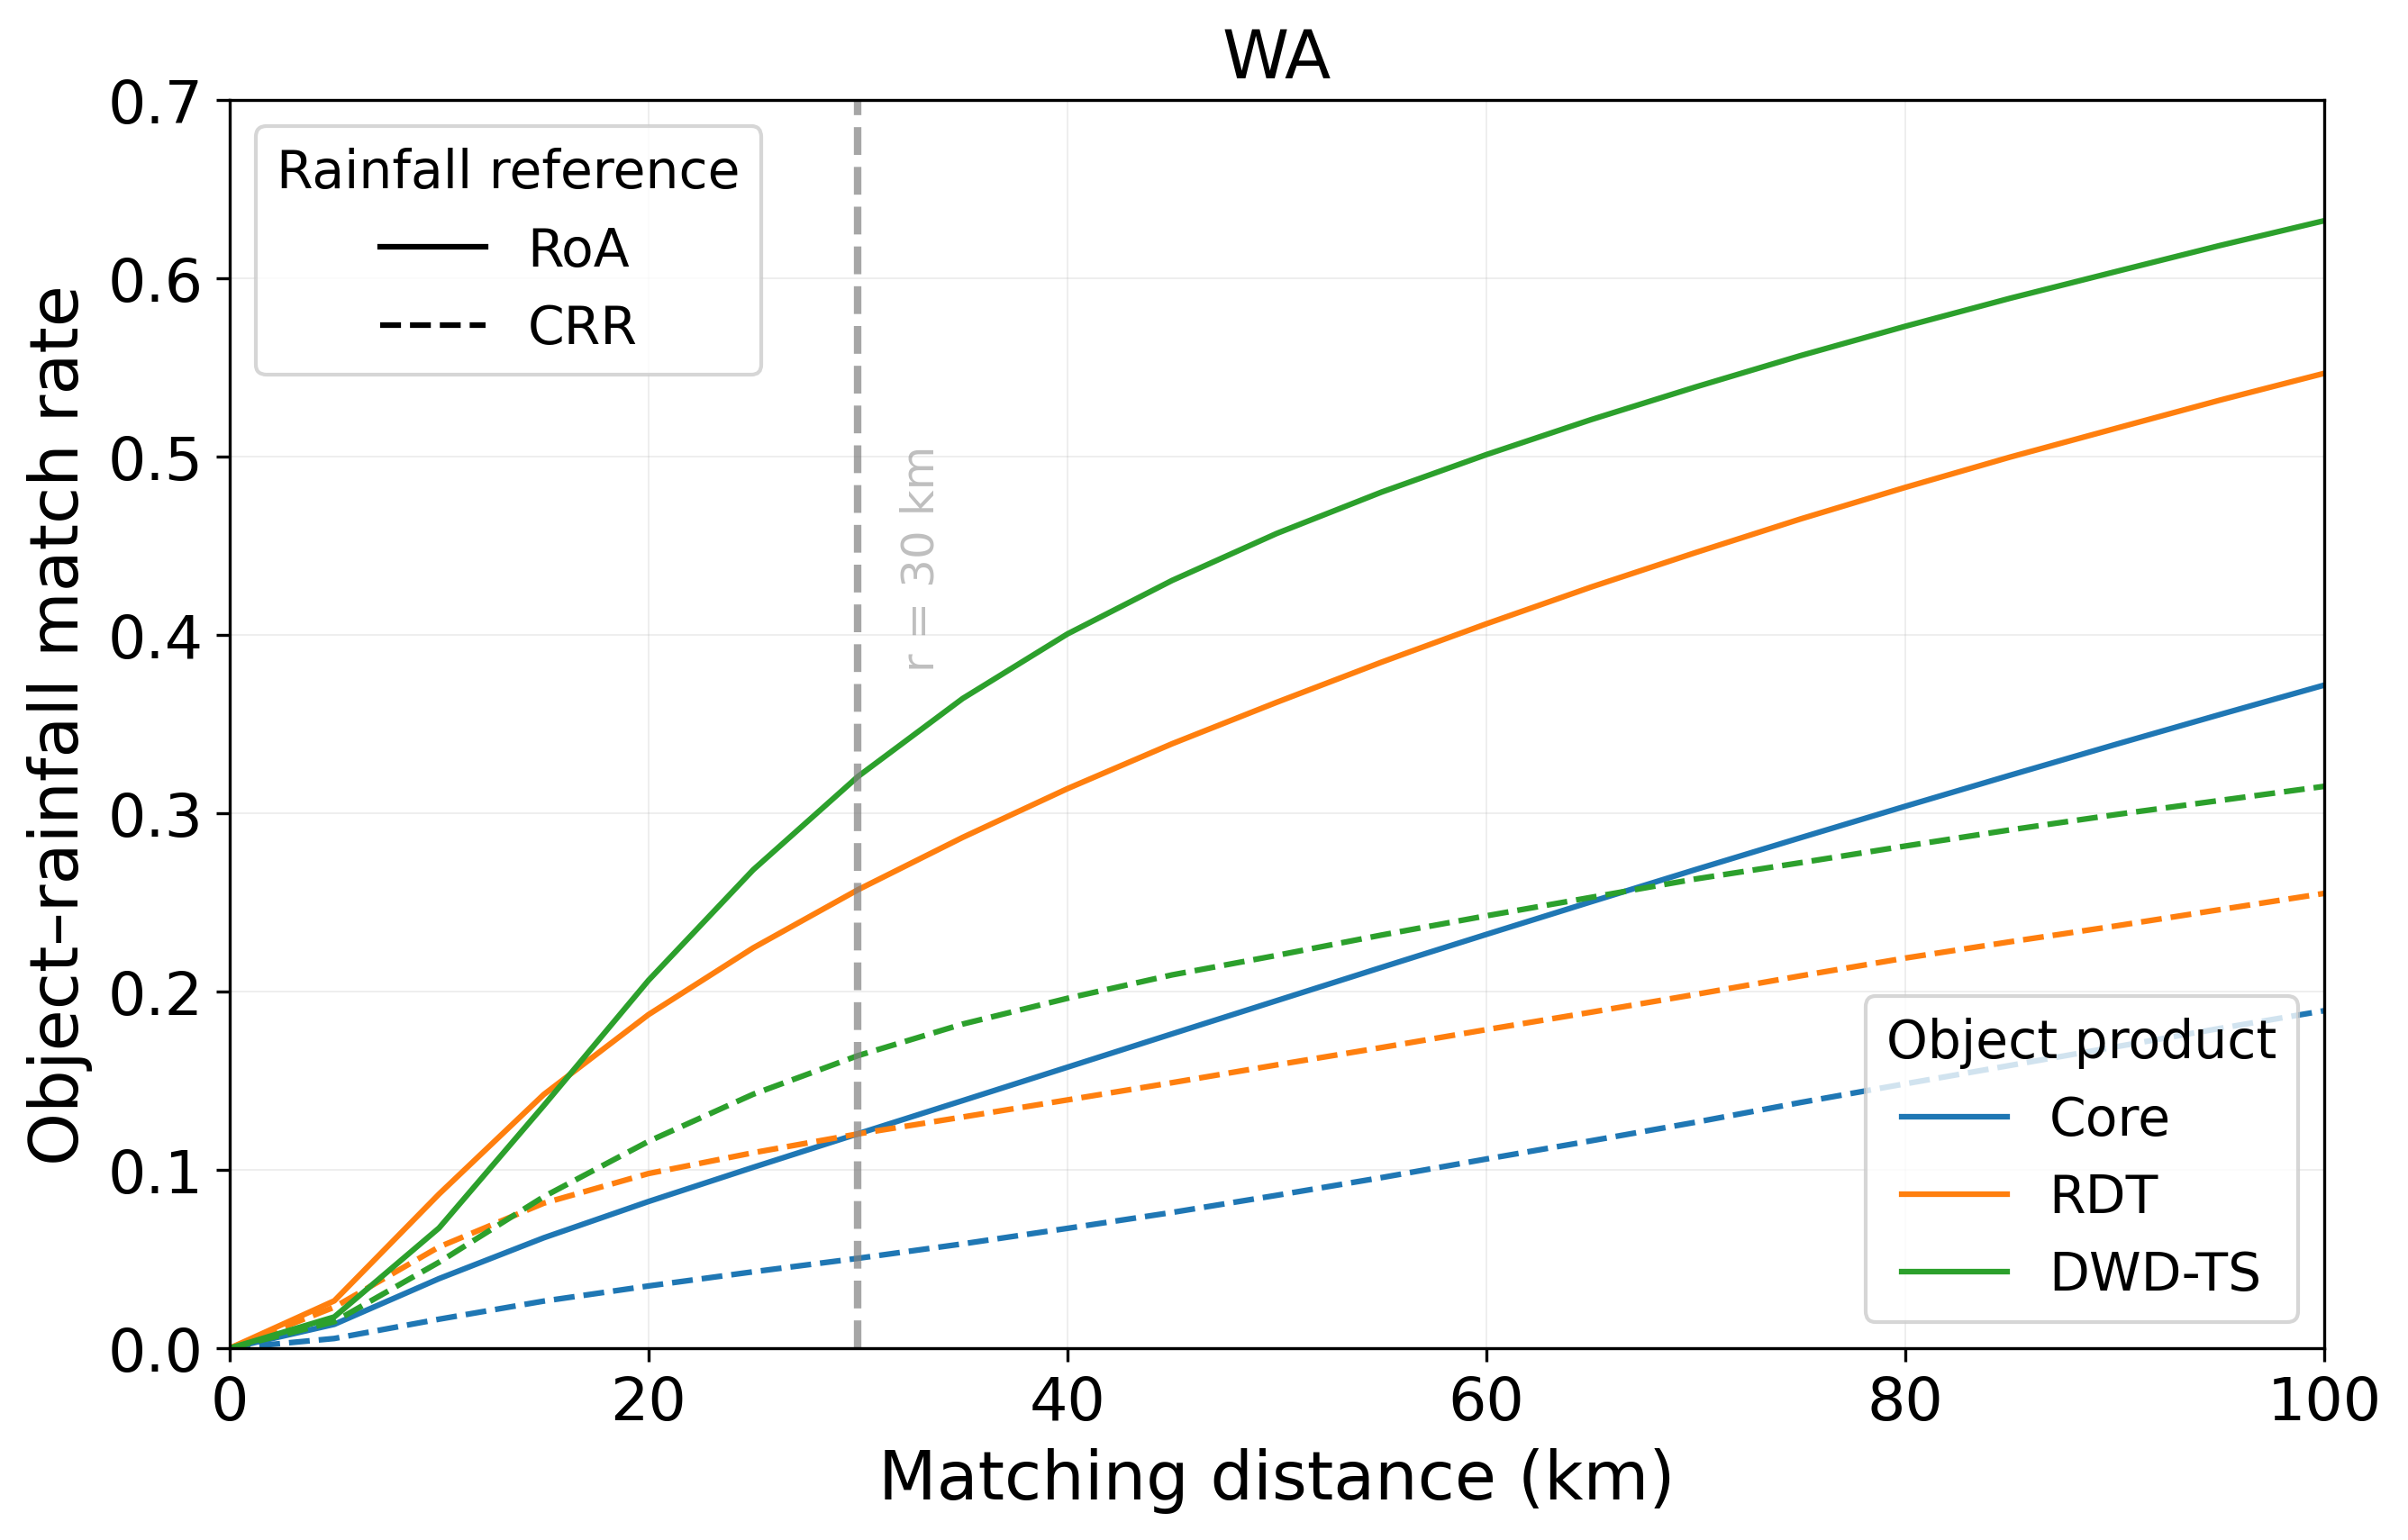

In [6]:
from matplotlib.lines import Line2D


radii = np.arange(0, 105, 5)

domains = ["CA", "EA", "SA", "WA"]

for domain in domains:

    # Calculate RoA match rates
    core_roa_rates = [
        np.mean(distances[domain]["core_roa"] <= r)
        for r in radii
    ]
    rdt_roa_rates = [
        np.mean(distances[domain]["rdt_roa"] <= r)
        for r in radii
    ]
    ts_roa_rates = [
        np.mean(distances[domain]["ts_roa"] <= r)
        for r in radii
    ]

    # Calculate CRR match rates
    core_crr_rates = [
        np.mean(distances[domain]["core_crr"] <= r)
        for r in radii
    ]
    rdt_crr_rates = [
        np.mean(distances[domain]["rdt_crr"] <= r)
        for r in radii
    ]
    ts_crr_rates = [
        np.mean(distances[domain]["ts_crr"] <= r)
        for r in radii
    ]

    plt.figure(figsize=(10, 6), dpi=300)

    # Plot Core
    core_line, = plt.plot(
        radii,
        core_roa_rates,
        linestyle="-",
    )
    plt.plot(
        radii,
        core_crr_rates,
        linestyle="--",
        color=core_line.get_color(),
    )

    # Plot RDT
    rdt_line, = plt.plot(
        radii,
        rdt_roa_rates,
        linestyle="-",
    )
    plt.plot(
        radii,
        rdt_crr_rates,
        linestyle="--",
        color=rdt_line.get_color(),
    )

    # Plot DWD-TS
    ts_line, = plt.plot(
        radii,
        ts_roa_rates,
        linestyle="-",
    )
    plt.plot(
        radii,
        ts_crr_rates,
        linestyle="--",
        color=ts_line.get_color(),
    )

    # Legend for rainfall references
    reference_handles = [
        Line2D(
            [0], [0],
            color="black",
            linestyle="-",
            label="RoA",
        ),
        Line2D(
            [0], [0],
            color="black",
            linestyle="--",
            label="CRR",
        ),
    ]

    reference_legend = plt.legend(
        handles=reference_handles,
        title="Rainfall reference",
        fontsize=14,
        title_fontsize=14,
        loc="upper left",
    )

    plt.gca().add_artist(reference_legend)

    # Legend for object products
    object_handles = [
        Line2D(
            [0], [0],
            color=core_line.get_color(),
            linestyle="-",
            label="Core",
        ),
        Line2D(
            [0], [0],
            color=rdt_line.get_color(),
            linestyle="-",
            label="RDT",
        ),
        Line2D(
            [0], [0],
            color=ts_line.get_color(),
            linestyle="-",
            label="DWD-TS",
        ),
    ]

    plt.legend(
        handles=object_handles,
        title="Object product",
        fontsize=14,
        title_fontsize=14,
        loc="lower right",
    )

    plt.xlabel("Matching distance (km)", fontsize=18)
    plt.ylabel("Object–rainfall match rate", fontsize=18)

    plt.xlim(0, 100)
    plt.ylim(0, 0.7)

    plt.axvline(
        30,
        color="grey",
        linestyle="--",
        linewidth=2,
        alpha=0.7,
    )

    plt.text(
        32,
        0.38,
        "r = 30 km",
        fontsize=12,
        color="grey",
        rotation=90,
        va="bottom",
        alpha=0.5,
    )

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.grid(True, linewidth=0.1)

    plt.title(domain, fontsize=18)

    plt.show()